A Simple Guide to Object Detection Using YOLOv8

This tutorial demonstrates how to train and use an object-detection model with Ultralytics's YOLOv8 in Python.

For the object-detection workflow used here, Ultralytics YOLO provides a convenient high-level interface for dataset configuration, model training, evaluation, and inference. As a result, a basic model can be trained with relatively little code once the dataset has been organised correctly.


The first step is to import the Python packages required for the tutorial.


In [1]:
from ultralytics import YOLO
import torch
import os
from PIL import Image
here = os.getcwd()

Preparing the dataset

YOLO uses a YAML configuration file to describe the dataset used for training. This file specifies the locations of the training, validation, and optional test images, together with the number and names of the object classes.

A simple two-class configuration can be organised as follows:

train:
    - "path to training image folder"

val:
    - "path to validation image folder"

test:
    - "path to test image folder"

nc: 2

names: ["circle", "square"]

The paths should be changed to match the location of your own dataset.


The images and object-detection labels must also be organised in a consistent directory structure. A practical arrangement is to keep each dataset or data source in its own folder, with separate images and labels subfolders.

For example:

Parent_folder
    data_set_folder
        images
            image_1.png
            image_2.png
            ...
        labels
            image_1.txt
            image_2.txt
            ...

The YAML file points to the images directory. YOLO then associates each image with the label file of the same base filename in the corresponding labels directory.

This structure can be repeated for separate training, validation, and test datasets, or for multiple data sources where required.


Each image is paired with a text file containing its object-detection labels. Every detected object is represented by one line using the YOLO format:

class_id x_center y_center width height

The coordinate and size values are normalised to the image dimensions and therefore range from 0 to 1.

For example:

1 0.5 0.5 0.5 0.5

represents an object from class 1 centred in the image with a bounding box spanning half of the image width and half of the image height.

Class numbering begins at 0. If an image contains no labelled objects, its corresponding label file contains no object entries.


In [3]:
here = os.getcwd()

data_folder = here+'/Yolo_test_shapes'
if not os.path.exists(data_folder):
    %run generationcodeforyolo.ipynb



Selecting a YOLOv8 model

YOLOv8 is available in several model sizes that provide different trade-offs between computational cost and model capacity.

The standard model configurations are:

Nano       = yolov8n.yaml
Small      = yolov8s.yaml
Medium     = yolov8m.yaml
Large      = yolov8l.yaml
ExtraLarge = yolov8x.yaml

This tutorial uses the Nano model to provide a relatively small and fast example. Larger models can be substituted when additional model capacity is required.


In [4]:
model = YOLO('yolov8n.yaml')  # build a new model from YAML

Training the model

The Ultralytics training interface provides a large number of configurable parameters. The example below uses only a small subset of the available settings.

Important parameters include:

data: the path to the YAML file describing the dataset.

epochs: the maximum number of training epochs.

imgsz: the image size supplied to the model during training.

batch: the number of images processed in each training batch. Automatic batch sizing can also be requested using the supported automatic setting.

close_mosaic: controls how many final training epochs are performed with mosaic augmentation disabled.

cache: controls whether images are cached to improve data-loading performance.

verbose: controls the amount of training information printed during execution.

Additional settings can be adjusted when adapting the tutorial to a larger or more complex object-detection problem.


In [5]:
###########################################################
# Train YOLO model
###########################################################

import os
import shutil

###########################################################
# Reset previous training folder
###########################################################

training_output_folder = "runs/detect/train"

if os.path.exists(training_output_folder):
    shutil.rmtree(training_output_folder)

###########################################################
# Train model
###########################################################

results = model.train(
    data="trainingdata_shapes.yaml",
    epochs=1000,
    patience=50,          # stop if model stops improving
    imgsz=640,
    batch=-64,             # automatically select batch size
    workers=0,            # avoids Windows/Jupyter multiprocessing problems
    verbose=False,        # reduce training output
    close_mosaic=0,       # use images as they are
    name="train",         # always call the run train
    exist_ok=True         # do not create train2, train3, etc.
)

New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.57  Python-3.13.9 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4080, 16376MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-64, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=trainingdata_shapes.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=1000, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0

Evaluating the trained model

Ultralytics saves the outputs from each training run in the runs directory. The generated files include plots and summaries that can be used to assess both dataset quality and model performance.

Two particularly useful outputs are the confusion matrix and the training-results plots. The confusion matrix summarises how the model's classifications are distributed across the available classes, while the results plots show how key training and validation metrics change during training.

These outputs should be reviewed before selecting a trained model for subsequent analysis.


Accessing the trained model

The weights subfolder generated during training contains two model files:

best.pt: the model checkpoint with the best validation performance recorded during training.

last.pt: the model checkpoint from the final training epoch.

For most subsequent inference tasks, best.pt is the appropriate starting point. The file can be copied to the required analysis directory and renamed to a descriptive filename for long-term use.


Using the trained model

The first step is to load the trained model by passing the saved model path to YOLO().

Once loaded, the model can be used to perform inference on new images.


In [6]:
pathtomodel = here+"//runs//detect//train//weights//best.pt"
model = YOLO(pathtomodel)


YOLO can accept image data in several common forms, including:

- a file path to an image;
- a NumPy array or tensor;
- a PIL image;
- an OpenCV image.

The following example loads an image and supplies it to the model for prediction.


In [7]:
###########################################################
# Make prediction on an image from the validation dataset
###########################################################

imagenumber = 20

validation_folder = "Yolo_test_shapes/val/images/"

###########################################################
# Get validation images
###########################################################

validation_images = [filename for filename in os.listdir(validation_folder) if filename.lower().endswith(".png")]

# Sort according to the number in image_#.png
validation_images = sorted(validation_images, key=lambda filename: int(filename.split("_")[-1].split(".")[0]))

###########################################################
# Select image
###########################################################

imagename = validation_images[imagenumber]

pathtoimage = validation_folder + imagename

image = Image.open(pathtoimage)

###########################################################
# Make prediction
###########################################################

prediction = model.predict(source=image)


0: 640x640 1 circle, 5.6ms
Speed: 2.3ms preprocess, 5.6ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)


Extracting prediction results

The prediction returned by YOLO contains the detected objects and associated model outputs. The following code demonstrates how to extract:

- bounding-box coordinates;
- prediction confidence;
- class ID;
- an annotated image showing the predicted bounding boxes, class labels, and confidence values.

These outputs can then be used directly in a larger image-analysis workflow or saved for later inspection.


Bounding boxes: tensor([[146.6643, 150.1364, 232.2523, 233.8306]], device='cuda:0')
Confidence scores: tensor([0.9934], device='cuda:0')
Class IDs: tensor([0.], device='cuda:0')


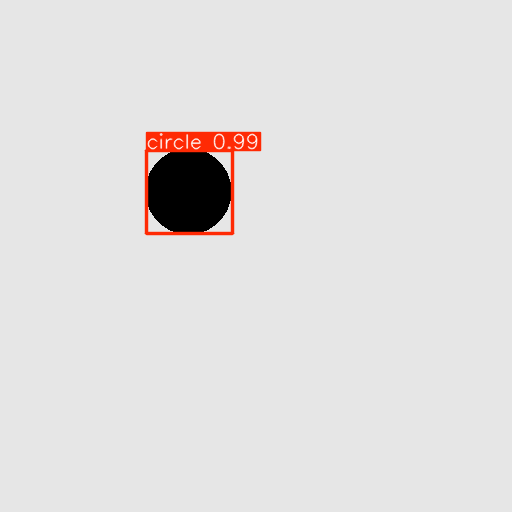

In [8]:
# Extract predictions
for result in prediction:  # Iterate through each prediction (useful for batches)
    
    # extracting data 
    boxes = result.boxes.xyxy  # Bounding box coordinates (x_min, y_min, x_max, y_max)
    confidences = result.boxes.conf  # Confidence scores
    classes = result.boxes.cls  # Class IDs
    annotated_image = result.plot()
    PIL_annotated_image = Image.fromarray(annotated_image)
    
    # Printing data 
    print("Bounding boxes:", boxes)
    print("Confidence scores:", confidences)
    print("Class IDs:", classes)
    display(PIL_annotated_image)

This completes the basic YOLOv8 object-detection workflow. The tutorial has demonstrated how to organise a YOLO dataset, configure the dataset using a YAML file, select and train a model, inspect the training outputs, load the resulting model, and extract object-detection predictions from new images.
